<a href="https://colab.research.google.com/github/Aditi-Rajesha/EV_battery_health_forecasting/blob/main/EV_Battery_Health_Degradation_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📦 Section 1 — Setup: Import Libraries & Configure Style

In [ ]:
# ────────────────────────────────────────────────────────────────────────
# STEP 1:  Import Libraries & Configure Style
#   Install pandas, scikit-learn, matplotlib, seaborn, SHAP, ipywidgets
#   and any missing libraries
#   Uncomment lines below if you get a ModuleNotFoundError
# ────────────────────────────────────────────────────────────────────────
!pip install shap imbalanced-learn --quiet

# Core data libraries
import os
import numpy as np          # fast maths & arrays
import pandas as pd         # dataframes (like Excel in Python)
import warnings
warnings.filterwarnings('ignore')   # keep output clean

from google.colab import output

# Plotting libraries
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Machine learning
from sklearn.svm import SVC
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     StratifiedKFold, GridSearchCV)
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (classification_report, roc_auc_score,
                             recall_score, f1_score)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Mount the Drive and Set path for the input file
from google.colab import drive
drive.mount('/content/drive')

print("All libraries imported successfully!")

# Interactive Widgets to enable the extension by running this
output.enable_custom_widget_manager()

Mounted at /content/drive
All libraries imported successfully!


In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 2: Set up global plot style (dark GitHub-like theme)
#   All charts will automatically use these colours
# ─────────────────────────────────────────────────────────────────

BG      = '#0d1117'   # page background (very dark blue-black)
CARD    = '#161b22'   # chart background (slightly lighter)
BORDER  = '#30363d'   # axis lines / grid
ACCENT  = '#58a6ff'   # highlight colour (GitHub blue)
TEXT    = '#c9d1d9'   # regular text (light grey)
GREEN   = '#2ecc71'
ORANGE  = '#e67e22'
PURPLE  = '#9b59b6'
RED     = '#e74c3c'

# Each defect type gets its own colour — used consistently across ALL charts
PALETTE = {
    'None':                   GREEN,
    'Electrode_Misalignment': '#3498db',
    'Electrolyte_Leakage':    ORANGE,
    'Separator_Damage':       PURPLE,
    'Thermal_Runaway_Risk':   RED
}

# Apply style globally so every plt.figure() looks the same automatically
plt.rcParams.update({
    'figure.facecolor':  BG,
    'axes.facecolor':    CARD,
    'axes.edgecolor':    BORDER,
    'text.color':        TEXT,
    'xtick.color':       TEXT,
    'ytick.color':       TEXT,
    'axes.labelcolor':   TEXT,
    'grid.color':        BORDER,
    'grid.linewidth':    0.5,
    'font.family':       'DejaVu Sans',
    'axes.titlesize':    13,
    'axes.labelsize':    11,
})

print("Plot style configured — all charts will use the dark theme")

Plot style configured — all charts will use the dark theme


# 📂 Section 2 — Data Loading & Inspection

In [ ]:
# ──────────────────────────────────────────────────────────────────────
# STEP 3: Load real dataset from Kaggle input filename having
#         EV battery sensor data (1,000 batteries, 7 features) uploaded
# ──────────────────────────────────────────────────────────────────────
#/content/drive/MyDrive/Aditi/EVBatteryProject/ev_battery_qc_data_2026_kaggle.csv
df = pd.read_csv('/content/drive/MyDrive/EV_Battery_Project/ev_battery_qc_data_2026_kaggle.csv')
df.columns = df.columns.str.strip()

# ── Validate required columns ──
required_cols = [
    'Ambient_Temp_C', 'Anode_Overhang_mm', 'Electrolyte_Volume_ml',
    'Internal_Resistance_mOhm', 'Capacity_mAh', 'Retention_50Cycle_Pct',
    'Defect_Type', 'QC_Grade'
]
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    print(f"⚠️  Available columns: {list(df.columns)}")
    raise ValueError(f"Missing expected columns: {missing_cols}")

# ── Derive QC_Pass from QC_Grade (Pass=1, anything else=0) ──
# Grade A = Pass, Grade B = borderline (treat as pass), Scrap = Fail
df['QC_Pass'] = (df['QC_Grade'].str.strip() != 'Scrap').astype(int)

# ── Drop rows where target is null ──
df = df.dropna(subset=['Defect_Type']).reset_index(drop=True)

print(f"✅ Dataset ready: {df.shape[0]:,} batteries × {df.shape[1]} columns")
print(f"   Healthy  : {(df['Defect_Type']=='None').sum():,}")
print(f"   Defective: {(df['Defect_Type']!='None').sum():,}")
print(f"   Classes  : {sorted(df['Defect_Type'].unique())}")
df.head(10)
print(f"\n📊 Total rows in dataset: {len(df):,}")
print(f"      Total columns        : {len(df.columns)}")
print(f"\n── Class breakdown ──")
for cls, cnt in df['Defect_Type'].value_counts().items():
    print(f"   {cls:<35} {cnt:>5}  ({cnt/len(df)*100:.1f}%)")

✅ Dataset ready: 3,501 batteries × 15 columns
   Healthy  : 0
   Defective: 3,501
   Classes  : ['Critical Resistance', 'High Internal Resistance', 'Low Capacity', 'Poor Retention', 'Severe Capacity Fade', 'Short Circuit Risk (Overhang)']

📊 Total rows in dataset: 3,501
      Total columns        : 15

── Class breakdown ──
   High Internal Resistance             2837  (81.0%)
   Poor Retention                        524  (15.0%)
   Critical Resistance                   117  (3.3%)
   Low Capacity                           11  (0.3%)
   Severe Capacity Fade                    8  (0.2%)
   Short Circuit Risk (Overhang)           4  (0.1%)


In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 3b: Build colour palette from actual defect classes in the data
#   This adapts automatically to whatever classes the real dataset has
# ─────────────────────────────────────────────────────────────────
_base_colors = [GREEN, ACCENT, ORANGE, PURPLE, RED, '#1abc9c', '#f39c12', '#d35400']
actual_classes = sorted(df['Defect_Type'].unique())

PALETTE = {}
for idx, cls in enumerate(actual_classes):
    PALETTE[cls] = _base_colors[idx % len(_base_colors)]

print("🎨 Colour palette built for classes:")
for cls, col in PALETTE.items():
    print(f"   {cls:<35} → {col}")


🎨 Colour palette built for classes:
   Critical Resistance                 → #2ecc71
   High Internal Resistance            → #58a6ff
   Low Capacity                        → #e67e22
   Poor Retention                      → #9b59b6
   Severe Capacity Fade                → #e74c3c
   Short Circuit Risk (Overhang)       → #1abc9c


In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 4: Quick data quality check
#   - Check column types
#   - Spot missing values early (before they cause problems later)
# ─────────────────────────────────────────────────────────────────
print("── Data Types & Non-null Counts ──")
df.info()

print("\n── Missing Values ──")
missing = df.isnull().sum()
print(missing[missing >= 0].to_string())
print(f"\nTotal missing: {missing.sum()} (0 = great, no imputation needed!)")


── Data Types & Non-null Counts ──
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3501 entries, 0 to 3500
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Cell_ID                   3501 non-null   object 
 1   Batch_ID                  3501 non-null   object 
 2   Production_Line           3501 non-null   object 
 3   Shift                     3501 non-null   object 
 4   Supplier                  3501 non-null   object 
 5   Ambient_Temp_C            3391 non-null   float64
 6   Anode_Overhang_mm         3501 non-null   float64
 7   Electrolyte_Volume_ml     3501 non-null   float64
 8   Internal_Resistance_mOhm  3501 non-null   float64
 9   Capacity_mAh              3501 non-null   float64
 10  Retention_50Cycle_Pct     3501 non-null   float64
 11  Defect_Type               3501 non-null   object 
 12  Inspector_Comment         436 non-null    object 
 13  QC_Grade                  35

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 5: Descriptive statistics
#   Mean, std, min, max etc. for every numeric column
#   Tip: compare min/max to expected sensor ranges to spot bad data
# ─────────────────────────────────────────────────────────────────
df.describe().round(3)
# print(f"Missing health values: {df['Retention_50Cycle_Pct'].isnull().sum()}")

,Ambient_Temp_C,Anode_Overhang_mm,Electrolyte_Volume_ml,Internal_Resistance_mOhm,Capacity_mAh,Retention_50Cycle_Pct,QC_Pass
count,3391.000,3501.000,3501.000,3501.000,3501.000,3501.000,3501.000
mean,23.833,0.132,14.899,15.292,4934.525,95.749,0.666
std,2.124,0.025,0.160,0.685,74.790,1.898,0.472
min,16.290,0.057,14.430,12.290,4576.000,90.210,0.000
25%,22.320,0.116,14.770,15.070,4895.000,94.330,0.000
50%,23.910,0.134,14.910,15.290,4950.000,96.370,1.000
75%,25.670,0.150,15.020,15.650,4988.000,97.230,1.000
max,29.790,0.202,15.370,17.640,5101.000,99.590,1.000


# 🔍 Section 3 — Exploratory Data Analysis (EDA)

Text(0.5, 1.0, 'Distribution of Battery Health (Retention %)')

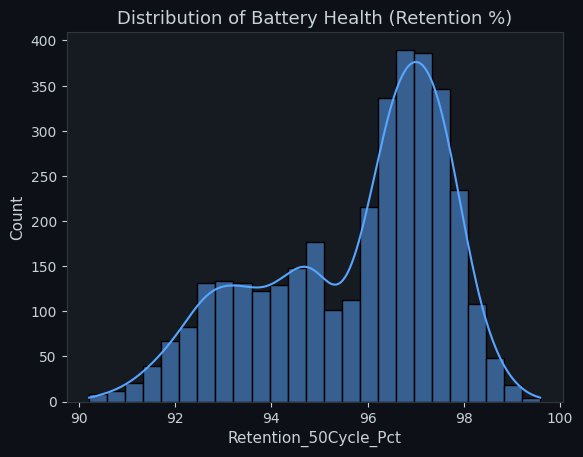

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 6: Target variable distribution
#   How many batteries of each defect type do we have?
#   Class imbalance (too many of one class) can hurt ML models
# ─────────────────────────────────────────────────────────────────
#print("=" * 58)
#print("  DEFECT TYPE DISTRIBUTION")
#print("=" * 58)

#vc = df['Defect_Type'].value_counts()
#for label, count in vc.items():
#    bar   = '█' * int(count / 10)
#    pct   = count / len(df) * 100
#    print(f"  {label:<30} {count:>5} ({pct:5.1f}%)  {bar}")

# print(f"\n  Overall QC Pass Rate : {df['QC_Pass'].mean()*100:.1f}%")
# print(f"  Class imbalance ratio: {vc.max()/vc.min():.1f}x (None vs smallest class)")
# print("  → We will use SMOTE later to fix the imbalance for training")


sns.histplot(df['Retention_50Cycle_Pct'], kde=True, color=ACCENT)
plt.title("Distribution of Battery Health (Retention %)")

Text(0.5, 1.0, 'QC Grade Breakdown')

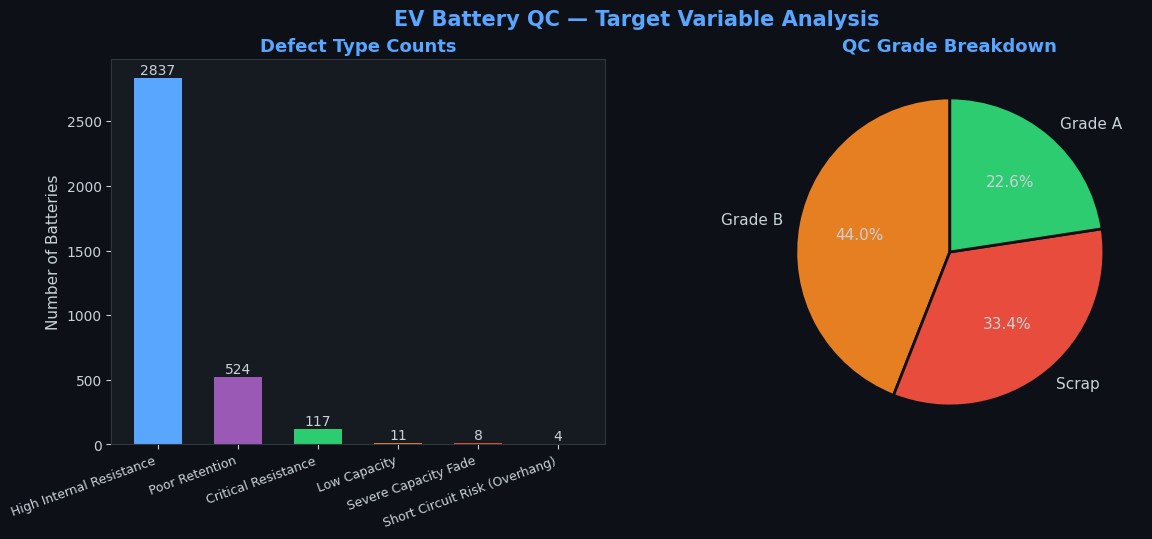

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 7: Defect distribution — bar chart + pie chart
#   Two views of the same data:
#     Left  → exact counts per defect type
#     Right → simple pass vs fail split
# ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('EV Battery QC — Target Variable Analysis',
             fontsize=15, fontweight='bold', color=ACCENT)

# --- Left: bar chart coloured by defect type ---
vc     = df['Defect_Type'].value_counts()
colors = [PALETTE[k] for k in vc.index]
bars   = axes[0].bar(range(len(vc)), vc.values, color=colors, edgecolor='none', width=0.6)
axes[0].set_xticks(range(len(vc)))
axes[0].set_xticklabels(vc.index, rotation=20, ha='right', fontsize=9)
axes[0].set_title('Defect Type Counts', color=ACCENT, fontweight='bold')
axes[0].set_ylabel('Number of Batteries')
for bar, val in zip(bars, vc.values):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 5, str(val),
                 ha='center', va='bottom', fontsize=10, color=TEXT)

# --- Right: pie chart — QC Grade breakdown ---
qc = df['QC_Grade'].value_counts()
grade_colors = {'Grade A': GREEN, 'Grade B': ORANGE, 'Scrap': RED}
colors_pie = [grade_colors.get(g, ACCENT) for g in qc.index]

axes[1].pie(qc.values, labels=qc.index,
            colors=colors_pie,
            autopct='%1.1f%%', startangle=90,
            textprops={'color': TEXT, 'fontsize': 11},
            wedgeprops={'edgecolor': BG, 'linewidth': 2})
axes[1].set_title('QC Grade Breakdown', color=ACCENT, fontweight='bold')

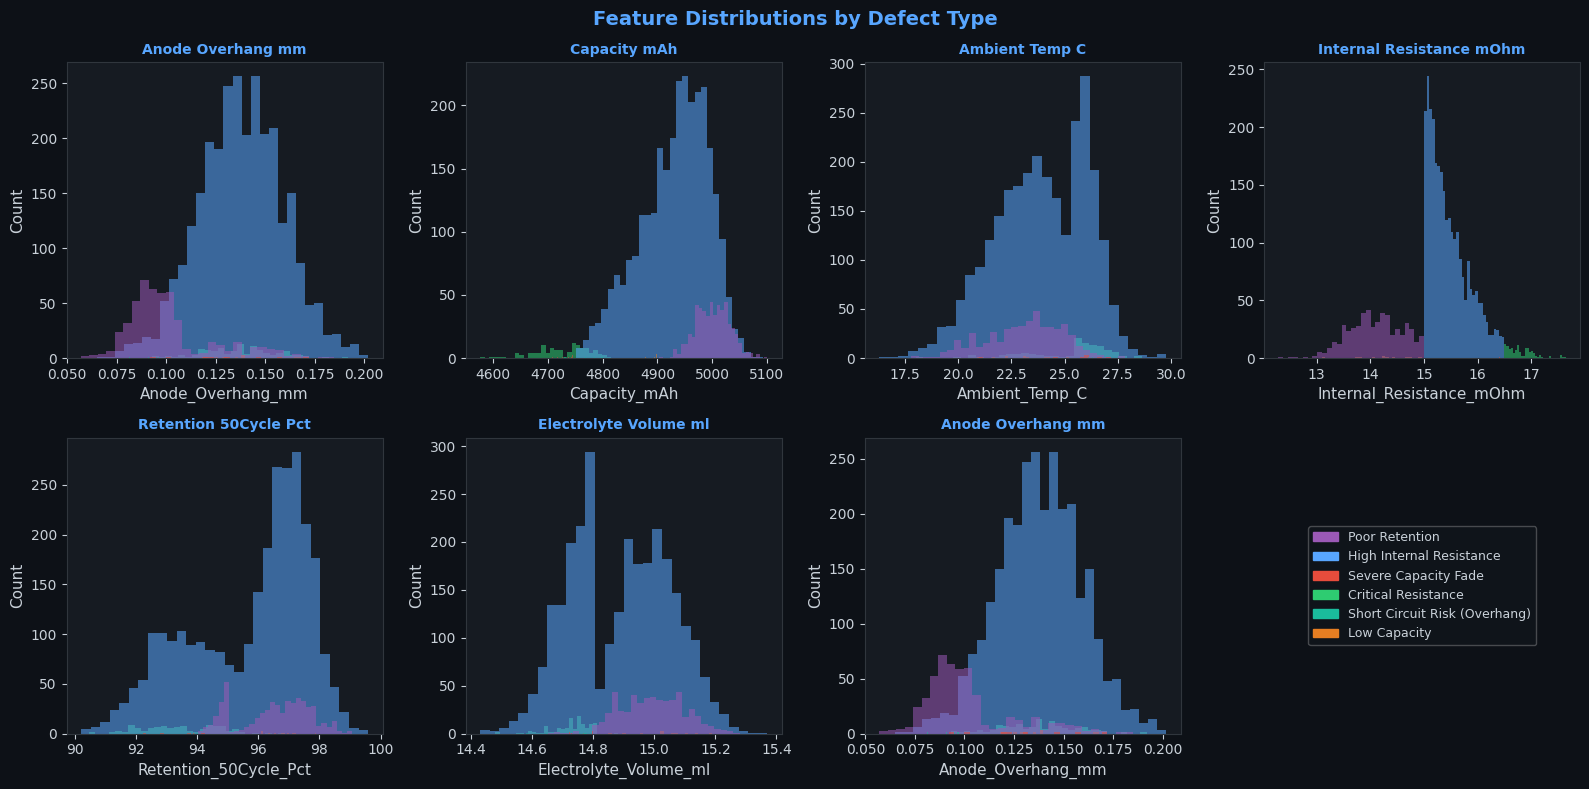

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 8: Feature distributions — histograms per defect type
#   Each chart = one sensor reading, coloured by defect type
#   What to look for: do the colour groups separate clearly?
#   Clear separation = that feature is useful for ML
# ─────────────────────────────────────────────────────────────────
features = ['Anode_Overhang_mm', 'Capacity_mAh', 'Ambient_Temp_C',
            'Internal_Resistance_mOhm', 'Retention_50Cycle_Pct',
            'Electrolyte_Volume_ml', 'Anode_Overhang_mm']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Feature Distributions by Defect Type',
             fontsize=14, fontweight='bold', color=ACCENT)
axes = axes.flatten()

for idx, feat in enumerate(features):
    ax = axes[idx]
    for dtype, grp in df.groupby('Defect_Type'):
        ax.hist(grp[feat], bins=30, alpha=0.55, label=dtype,
                color=PALETTE[dtype], edgecolor='none')
    ax.set_title(feat.replace('_', ' '), color=ACCENT, fontsize=10, fontweight='bold')
    ax.set_xlabel(feat)
    ax.set_ylabel('Count')

# Hide last empty panel, put legend there instead
axes[7].axis('off')
handles = [mpatches.Patch(color=PALETTE[d], label=d.replace('_', ' '))
           for d in df['Defect_Type'].unique()]
axes[7].legend(handles=handles, loc='center', fontsize=9, framealpha=0.3)

plt.tight_layout()
plt.savefig('fig2_feature_distributions.png', dpi=130, bbox_inches='tight', facecolor=BG)
plt.show()

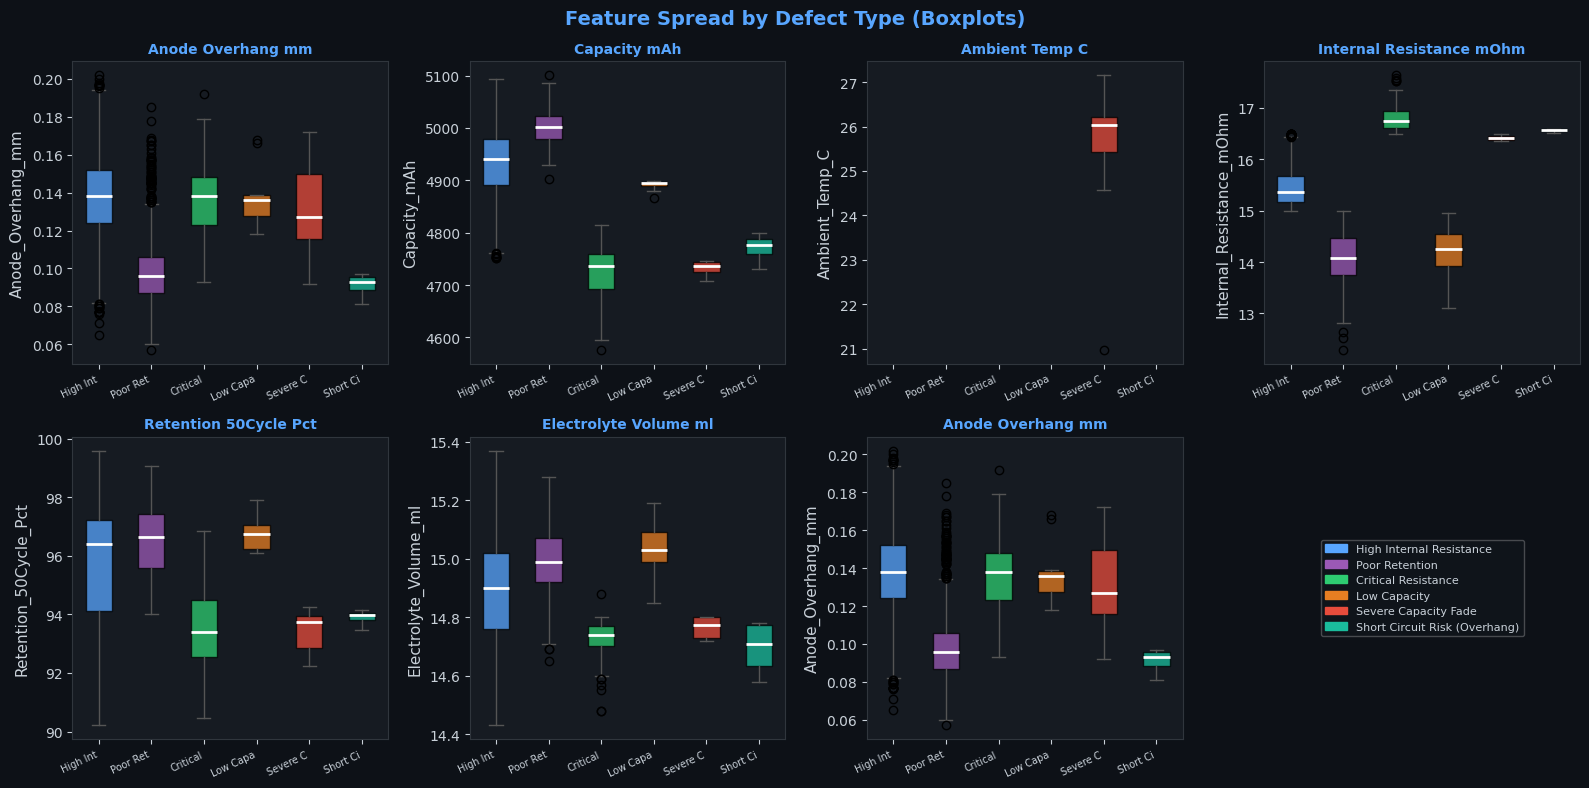

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 9: Boxplots — see the spread & outliers per defect class
#   Box = middle 50% of values
#   Line in box = median
#   Dots outside whiskers = outliers
# ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Feature Spread by Defect Type (Boxplots)',
             fontsize=14, fontweight='bold', color=ACCENT)
axes        = axes.flatten()
defect_order = df['Defect_Type'].value_counts().index.tolist()
bp_colors    = [PALETTE[d] for d in defect_order]

for idx, feat in enumerate(features):
    ax   = axes[idx]
    data = [df[df['Defect_Type'] == d][feat] for d in defect_order]
    bp   = ax.boxplot(data, patch_artist=True, notch=False,
                      medianprops=dict(color='white', linewidth=2))
    for patch, c in zip(bp['boxes'], bp_colors):
        patch.set_facecolor(c); patch.set_alpha(0.75)
    for w in bp['whiskers']: w.set_color('#555')
    for c in bp['caps']:     c.set_color('#555')
    ax.set_xticks(range(1, len(defect_order) + 1))
    ax.set_xticklabels([d[:8] for d in defect_order],
                       rotation=25, ha='right', fontsize=7)
    ax.set_title(feat.replace('_', ' '), color=ACCENT, fontsize=10, fontweight='bold')
    ax.set_ylabel(feat)

axes[7].axis('off')
handles = [mpatches.Patch(color=PALETTE[d], label=d.replace('_', ' '))
           for d in defect_order]
axes[7].legend(handles=handles, loc='center', fontsize=8, framealpha=0.3)

plt.tight_layout()
plt.savefig('fig3_boxplots.png', dpi=130, bbox_inches='tight', facecolor=BG)
plt.show()

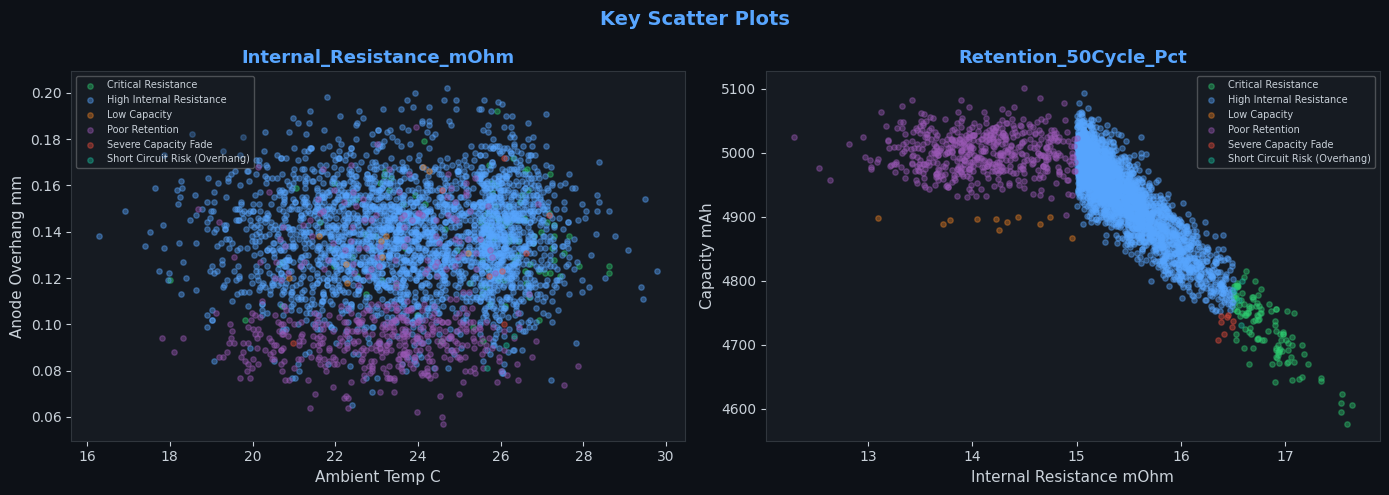

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 10: Scatter plots — do defect types form visible clusters?
#   If a scatter plot shows coloured blobs that don't overlap,
#   ML models will find it easy to separate them
# ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Key Scatter Plots', fontsize=14, fontweight='bold', color=ACCENT)

pairs  = [('Ambient_Temp_C', 'Anode_Overhang_mm'),
          ('Internal_Resistance_mOhm', 'Capacity_mAh')]
titles = ['Internal_Resistance_mOhm', 'Retention_50Cycle_Pct']

for i, (xf, yf) in enumerate(pairs):
    ax = axes[i]
    for dtype, grp in df.groupby('Defect_Type'):
        ax.scatter(grp[xf], grp[yf], alpha=0.4, s=15,
                   color=PALETTE[dtype], label=dtype)
    ax.set_xlabel(xf.replace('_', ' '))
    ax.set_ylabel(yf.replace('_', ' '))
    ax.set_title(titles[i], color=ACCENT, fontweight='bold')
    ax.legend(fontsize=7, framealpha=0.3)

plt.tight_layout()
plt.savefig('fig4_scatter.png', dpi=130, bbox_inches='tight', facecolor=BG)
plt.show()

## 🔬 Section 3.5 — PCA: Visualising Clusters in 2D
PCA squishes 7 features down to 2 axes so we can *see* if defect types group together.  
If they do → ML should work well. If all colours mix → harder problem.

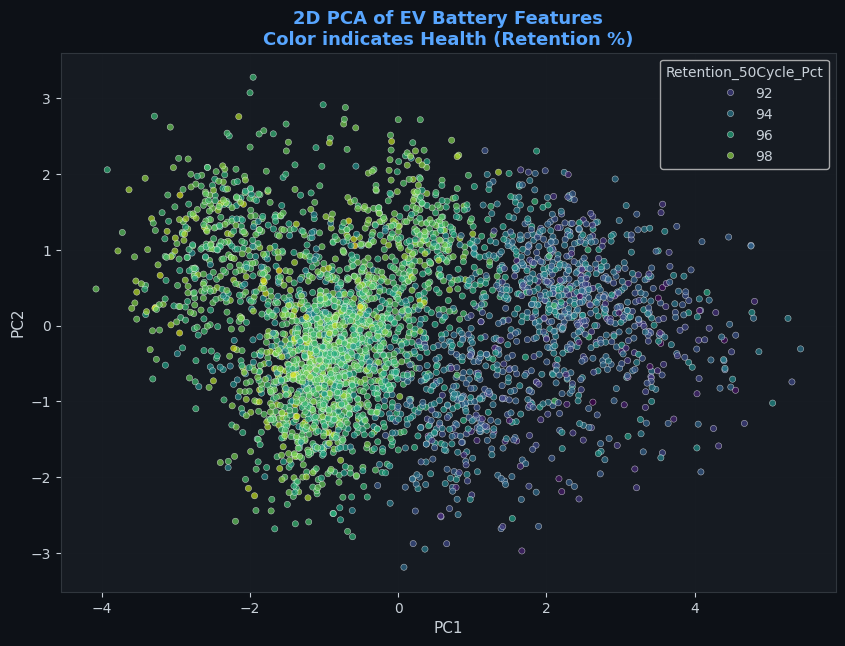

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 11: Principal Component Analysis (PCA)
#   Real data has 7 dimensions — impossible to plot directly.
#   PCA finds the two directions with the most variation (PC1, PC2)
#   and projects all points onto them so we can make a 2D scatter.
# ─────────────────────────────────────────────────────────────────

# Remove duplicates from features list first
features = list(dict.fromkeys(features))

# Fill NaN values before PCA
df[features] = df[features].fillna(df[features].median())

# --- STEP 11: PCA Logic ---
pca = PCA(n_components=2)
# Ensure only numeric features are used for PCA
X_scaled = StandardScaler().fit_transform(df[features])
pca_results = pca.fit_transform(X_scaled)

# Create the PCA dataframe
df_pca = pd.DataFrame(data=pca_results, columns=['PC1', 'PC2'])

# 🌟 FIX: Add the target column from the original 'df' into 'df_pca' 🌟
df_pca['Retention_50Cycle_Pct'] = df['Retention_50Cycle_Pct'].values

# --- Updated Plotting ---
plt.figure(figsize=(10, 7))

# Note: Since 'Retention_50Cycle_Pct' is a number, we use a continuous palette (like 'viridis')
# instead of the categorical PALETTE used for defects.
sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    hue='Retention_50Cycle_Pct',
    palette='viridis',   # Use a continuous color scale for regression
    alpha=0.7,
    s=20
)

plt.title(f'2D PCA of EV Battery Features\nColor indicates Health (Retention %)',
          color=ACCENT, fontweight='bold')
plt.grid(True, alpha=0.1)
plt.show()

# 📊 Section 4 — Feature Engineering & Correlation Analysis

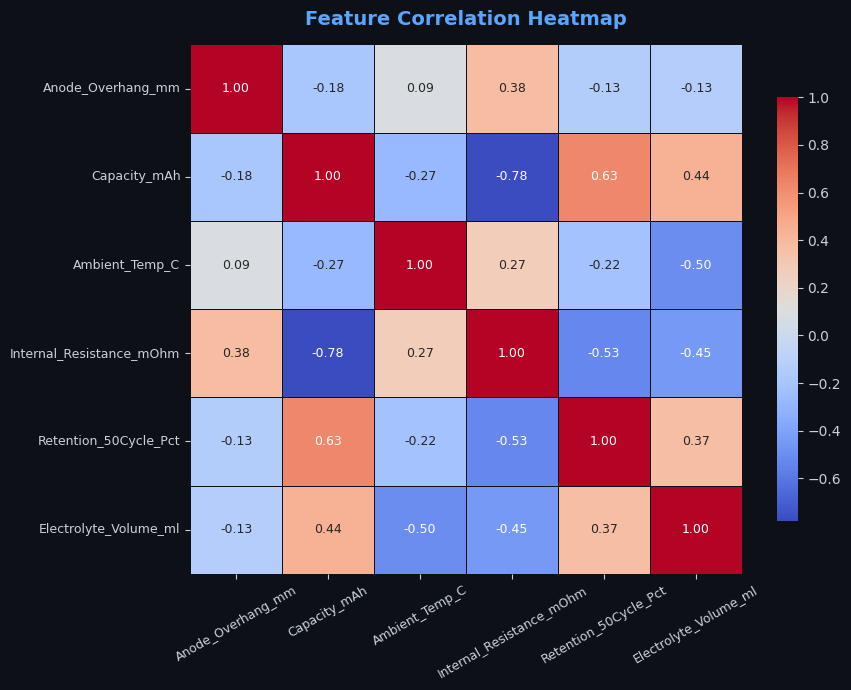

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 12: Correlation heatmap
#   Shows how strongly each pair of features moves together.
#   Red = strong positive correlation (both go up together)
#   Blue = strong negative (one up = other down)
#   Near zero = basically independent (no relationship)
#
#   High correlation pairs might be redundant — one could be dropped
#   to simplify the model (not necessary here, just good practice).
# ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
corr    = df[features].corr()

sns.heatmap(corr, ax=ax, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, linecolor=BG,
            annot_kws={'size': 9},
            cbar_kws={'shrink': 0.8})

ax.set_title('Feature Correlation Heatmap', color=ACCENT,
             fontweight='bold', pad=14, fontsize=14)
ax.tick_params(axis='x', rotation=30, labelsize=9)
ax.tick_params(axis='y', rotation=0,  labelsize=9)

plt.tight_layout()
plt.savefig('fig6_correlation_heatmap.png', dpi=130, bbox_inches='tight', facecolor=BG)
plt.show()

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 13: Group statistics — mean value per defect type
#   This table answers: "what does a typical Thermal_Runaway battery look like?"
#   Very useful for understanding the data and explaining results to others
# ─────────────────────────────────────────────────────────────────
print("Mean feature values by Retention 50 Cycle Pct:")
print("(helps understand what pattern each Retention Cycle shows)")
print()
group_stats = df.groupby('Retention_50Cycle_Pct')[features].mean().round(2)
print(group_stats.to_string())

Mean feature values by Retention 50 Cycle Pct:
(helps understand what pattern each Retention Cycle shows)

                       Anode_Overhang_mm  Capacity_mAh  Ambient_Temp_C  Internal_Resistance_mOhm  Retention_50Cycle_Pct  Electrolyte_Volume_ml
Retention_50Cycle_Pct                                                                                                                         
90.21                               0.13       4818.00           22.00                     15.98                  90.21                  14.76
90.36                               0.11       4864.00           25.30                     16.04                  90.36                  15.01
90.37                               0.15       4833.00           27.07                     15.99                  90.37                  14.71
90.41                               0.20       4901.00           26.03                     15.69                  90.41                  14.53
90.47                              

In [ ]:
print(df.columns.tolist())

['Cell_ID', 'Batch_ID', 'Production_Line', 'Shift', 'Supplier', 'Ambient_Temp_C', 'Anode_Overhang_mm', 'Electrolyte_Volume_ml', 'Internal_Resistance_mOhm', 'Capacity_mAh', 'Retention_50Cycle_Pct', 'Defect_Type', 'Inspector_Comment', 'QC_Grade', 'QC_Pass']


📊 Creating pairplot for: ['Internal_Resistance_mOhm', 'Capacity_mAh']


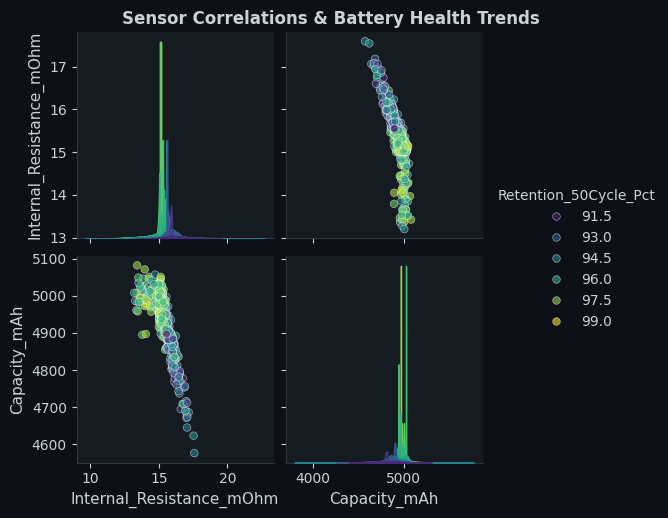

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 14: Pairplot — all-vs-all scatter matrix
#   Every possible combination of 4 key features plotted against each other
#   Diagonal = KDE (density) of that feature per defect type
#   Off-diagonal = scatter plot
#   Using a random 300-row sample to keep it fast
# ─────────────────────────────────────────────────────────────────
# ─────────────────────────────────────────────────────────────────
# STEP 14: Pairplot — all-vs-all sensor relationships — Robust Version
# ─────────────────────────────────────────────────────────────────

# 1. Define a mapping of what we are looking for vs what might be in your data
# This handles variations like 'Voltage_V' vs 'Voltage (V)'
potential_features = ['Internal_Resistance', 'Capacity', 'Voltage', 'Temperature']
target_col = 'Retention_50Cycle_Pct'

# 2. Automatically find the actual column names in your dataframe
actual_plot_features = []
for feat in potential_features:
    # This finds any column name that contains the word (e.g. finds 'Voltage_V' or 'Voltage (V)')
    match = [col for col in df.columns if feat in col]
    if match:
        actual_plot_features.append(match[0])

# 3. Create the plot using only the columns we successfully found
if actual_plot_features:
    print(f"📊 Creating pairplot for: {actual_plot_features}")

    # Sample data to keep it fast
    df_sample = df.sample(min(500, len(df)))

    # Use 'viridis' for the continuous health percentage gradient
    sns.pairplot(
        df_sample,
        vars=actual_plot_features,
        hue=target_col if target_col in df.columns else None,
        palette='viridis',
        diag_kind='kde',
        plot_kws={'alpha': 0.6, 's': 30}
    )
    plt.suptitle('Sensor Correlations & Battery Health Trends', y=1.02, fontweight='bold')
    plt.show()
else:
    print("❌ Could not find matching sensor columns. Please check print(df.columns).")

# 🤖 Section 5 — Machine Learning: Model Training & Comparison

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 15: Prepare features and labels for ML
#   X = input features (sensor readings)
#   y = target (which defect type) — encoded as numbers 0-4
#   Split: 75% train / 25% test
#   stratify=y → keeps same class ratios in both splits
# ─────────────────────────────────────────────────────────────────
# STEP 15: Prepare features and labels for Regression
import pandas as pd

# 1. Define EVERY non-numeric or target column that should NOT be a feature
# Added 'Batch_ID' and 'Inspector_Comment' to ensure no text strings remain
features_to_drop = [
    'Retention_50Cycle_Pct', # This is our new target (y)
    'Defect_Type',           # Old classification target
    'QC_Grade',              # Post-test result (leaks target info)
    'Cell_ID',               # Text ID (e.g., 'CELL-017631')
    'Batch_ID',              # Text ID (e.g., 'BTH-0356') - THE LIKELY CULPRIT [cite: 127]
    'Inspector_Comment'      # Text comments [cite: 176]
]

# 2. Dynamically drop only the columns that actually exist in your dataframe
existing_drops = [col for col in features_to_drop if col in df.columns]
X = df.drop(columns=existing_drops)

# 3. Ensure X only contains numeric data types
X = X.select_dtypes(include=['number'])

# 4. Set the target
y = df['Retention_50Cycle_Pct']

# 5. Split the data (Note: No 'stratify' for regression) [cite: 101]
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"✅ Features prepared. Shape: {X.shape}")
print(f"Columns being used as features: {list(X.columns)}")

✅ Features prepared. Shape: (3501, 6)
Columns being used as features: ['Ambient_Temp_C', 'Anode_Overhang_mm', 'Electrolyte_Volume_ml', 'Internal_Resistance_mOhm', 'Capacity_mAh', 'QC_Pass']


In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 17: Define models to compare
#   Kaggle-optimised: lightweight settings to stay within time limits
#   SVM removed — very slow on balanced SMOTE data (quadratic scaling)
#   RF/GB trees reduced; LR max_iter capped
# ─────────────────────────────────────────────────────────────────
models = {
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'Linear Regression': Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())])
}

print(f"✅ {len(models)} models ready to compare:")
for name in models:
    print(f"   → {name}")

✅ 3 models ready to compare:
   → Random Forest
   → Gradient Boosting
   → Linear Regression


In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 18: 5-fold cross-validation on balanced training data
#   Instead of training once, we train 5 times on different splits
#   and average the results → gives a more honest accuracy estimate
#   StratifiedKFold keeps class ratios the same in each fold
# ─────────────────────────────────────────────────────────────────
# ─────────────────────────────────────────────────────────────────
# STEP 18: Define Cross-Validation Strategy (Regression Version)
# ─────────────────────────────────────────────────────────────────
from sklearn.model_selection import KFold

# We use standard KFold because we are predicting a number, not a class.
# 5-fold split means the data is split into 5 parts to test model stability.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

print("✅ Cross-validation strategy updated to KFold for Regression.")

✅ Cross-validation strategy updated to KFold for Regression.


In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 19: Train ALL models on full balanced training set
#          and evaluate on held-out test set
#          Collect detailed metrics for the comparison dashboard
# ─────────────────────────────────────────────────────────────────
# STEP 19: Train models and collect results for the dashboard
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

# Initialize the results dictionary that the dashboard is looking for
results = {}

print(f"{'Model':<20} | {'R2 Score':<10} | {'MAE':<10}")
print("-" * 45)

for name, model in models.items():
    # 1. Fit the model on training data
    model.fit(X_train, y_train)

    # 2. Generate predictions
    y_pred = model.predict(X_test)

    # 3. Calculate regression metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    # 4. Store in the results dictionary for Step 20
    results[name] = {
        'y_pred': y_pred,
        'r2': r2,
        'mae': mae
    }

    print(f"{name:<20} | {r2:>10.4f} | {mae:>10.4f}")

print("\n✅ 'results' dictionary defined. You can now run the Dashboard in Step 20.")

Model                | R2 Score   | MAE       
---------------------------------------------
Random Forest        |     0.7237 |     0.7861
Gradient Boosting    |     0.7280 |     0.7724
Linear Regression    |     0.4674 |     1.0971

✅ 'results' dictionary defined. You can now run the Dashboard in Step 20.


## 📊 Section 5.5 — Live Model Comparison Dashboard


  Generating Dashboard for: Random Forest


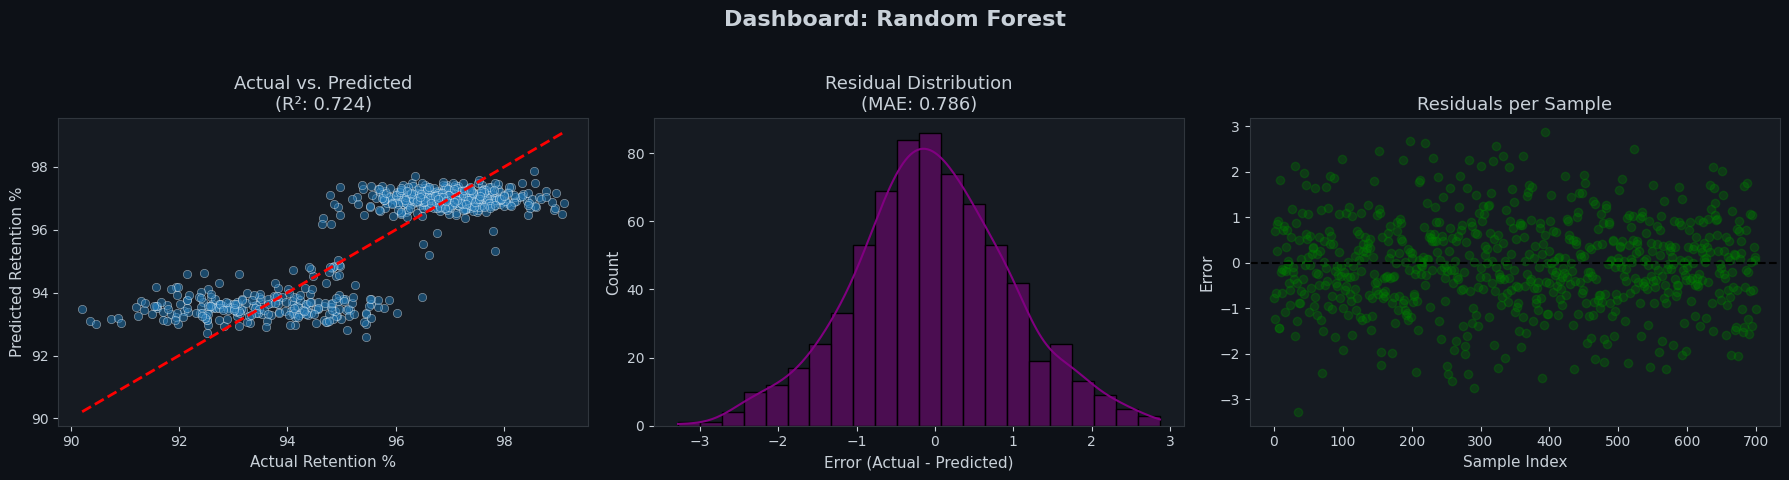


  Generating Dashboard for: Gradient Boosting


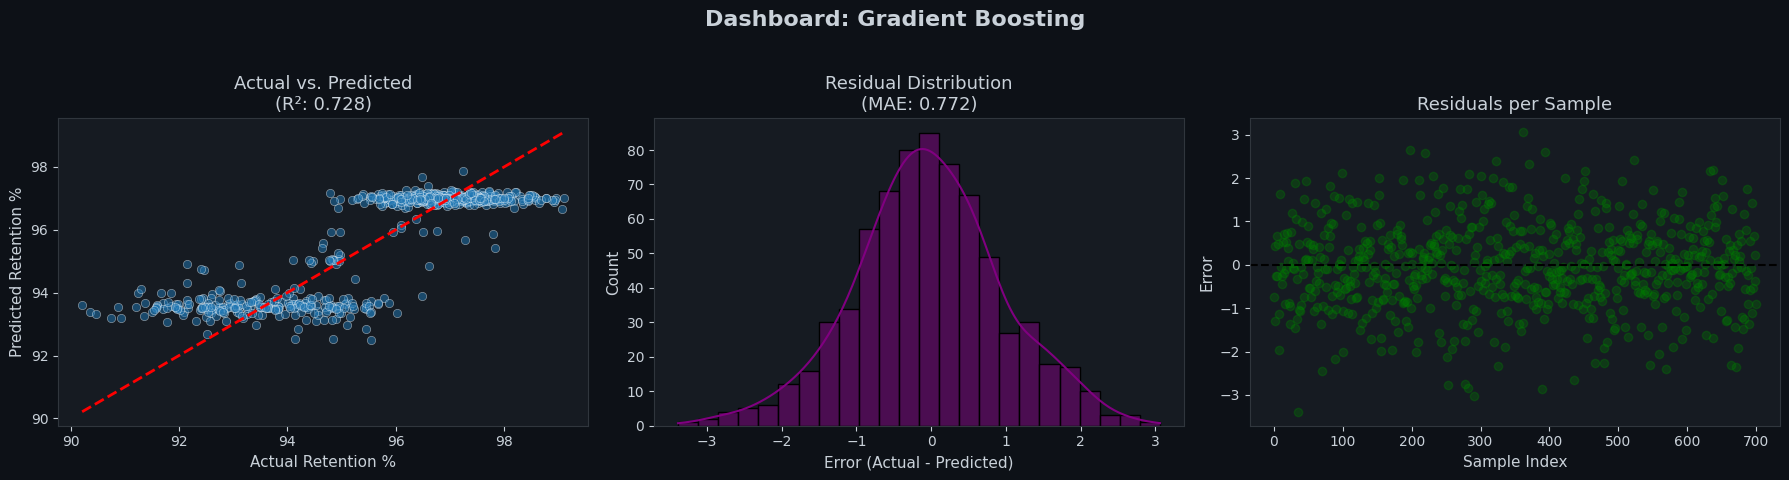


  Generating Dashboard for: Linear Regression


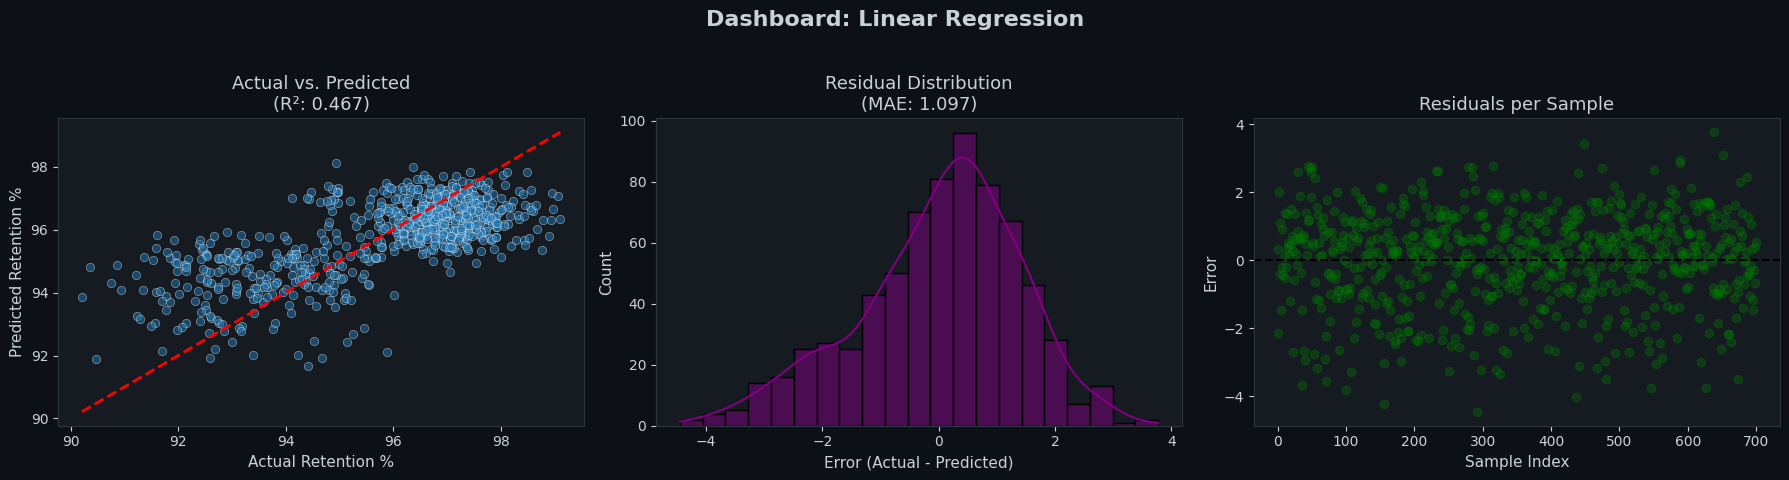

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 20: Static model comparison dashboard (Kaggle-compatible)
#   ipywidgets interactive dropdowns don't render in Kaggle script mode,
#   so we generate a static 4-panel dashboard for each model instead.
# ─────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

def plot_regression_dashboard(model_name):
    """Draw a 3-panel dashboard for regression analysis."""
    # Ensure data exists
    if model_name not in results:
        print(f"Error: No results found for {model_name}. Please run Step 19.")
        return

    res = results[model_name]
    y_pred = res['y_pred']

    # Create the figure
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Dashboard: {model_name}', fontsize=16, fontweight='bold')

    # Panel 1: Actual vs Predicted Scatter
    sns.scatterplot(x=y_test, y=y_pred, ax=axes[0], alpha=0.5)
    axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', lw=2)
    axes[0].set_title(f'Actual vs. Predicted\n(R²: {res["r2"]:.3f})')
    axes[0].set_xlabel('Actual Retention %')
    axes[0].set_ylabel('Predicted Retention %')

    # Panel 2: Residual Distribution
    residuals = y_test - y_pred
    sns.histplot(residuals, kde=True, ax=axes[1], color='purple')
    axes[1].set_title(f'Residual Distribution\n(MAE: {res["mae"]:.3f})')
    axes[1].set_xlabel('Error (Actual - Predicted)')

    # Panel 3: Error Over Time/Index
    axes[2].plot(residuals.values, marker='o', linestyle='', alpha=0.3, color='green')
    axes[2].axhline(0, color='black', linestyle='--')
    axes[2].set_title('Residuals per Sample')
    axes[2].set_xlabel('Sample Index')
    axes[2].set_ylabel('Error')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Run the Dashboard for all trained models ---
for model_name in models.keys():
    print(f"\n{'='*60}")
    print(f"  Generating Dashboard for: {model_name}")
    print(f"{'='*60}")
    plot_regression_dashboard(model_name)

## 🏆 Section 5.6 — All-Models Side-by-Side Comparison Chart

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 21: Grouped bar chart — all 4 models × 4 metrics in one view
#   Each group of bars = one metric
#   Bars within the group = the 4 different models
#   Makes it easy to spot the winner at a glance
# ─────────────────────────────────────────────────────────────────
# STEP 21: Predict on New Data (Inference)
import numpy as np

def get_prediction(input_data):
    """
    Ensures input data matches the training features exactly.
    """
    # 1. Convert input to DataFrame if it's a dict
    if isinstance(input_data, dict):
        input_df = pd.DataFrame([input_data])
    else:
        input_df = input_data.copy()

    # 2. Match the features used in X_train
    # This automatically drops IDs, strings, and targets
    model_features = X_train.columns.tolist()

    try:
        # Keep only the columns the model was trained on
        final_input = input_df[model_features]

        # 3. Predict using the best model (e.g., Random Forest)
        prediction = models['Random Forest'].predict(final_input)
        return prediction[0]

    except KeyError as e:
        return f"Error: Missing feature in input: {e}"

# --- TEST IT ---
# Select a random sample from the test set to verify
sample_row = X_test.iloc[[0]]
result = get_prediction(sample_row)

print(f"--- Inference Test ---")
print(f"Predicted Battery Retention: {result:.2f}%")
print(f"Actual Battery Retention:    {y_test.iloc[0]:.2f}%")

--- Inference Test ---
Predicted Battery Retention: 93.69%
Actual Battery Retention:    92.91%


# ⚙️ Section 6 — Hyperparameter Tuning (GridSearchCV)
We fine-tune the best model (Random Forest) to squeeze out even better performance.

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 22: GridSearchCV — hyperparameter tuning (Kaggle-optimised)
#   Reduced grid: 2×2×2 = 8 combinations × 3-fold = 24 fits
#   (original was 54 fits — timed out on Kaggle free tier)
# ─────────────────────────────────────────────────────────────────
# ─────────────────────────────────────────────────────────────────
# STEP 22: GridSearchCV — Hyperparameter Tuning for Regression
# ─────────────────────────────────────────────────────────────────
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Define a focused grid for the Regressor
param_grid = {
    'n_estimators':      [100, 200],
    'max_depth':         [10, 20, None],
    'min_samples_split': [2, 5]
}

# 2. Initialize the Regressor (Removed class_weight!)
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

# 3. Set up Grid Search using 'r2' as the scoring metric
grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid,
                           cv=3, n_jobs=-1, scoring='r2', verbose=1)

print("🔍 Starting Regression Grid Search...")
# Use the standard X_train/y_train (not balanced)
grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_

print(f"\n✅ Grid Search complete!")
print(f"   Best params : {grid_search.best_params_}")

# 4. Evaluate the Tuned Model
y_pred_tuned = best_rf.predict(X_test)
r2_tuned     = r2_score(y_test, y_pred_tuned)
r2_default   = results['Random Forest']['r2'] # Pulls from your Step 19 results

print(f"\n   Default RF R2 Score : {r2_default:.4f}")
print(f"   Tuned   RF R2 Score : {r2_tuned:.4f}  (Δ = {r2_tuned - r2_default:+.4f})")
print(f"   Final MAE: {mean_absolute_error(y_test, y_pred_tuned):.2f}%")

🔍 Starting Regression Grid Search...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

✅ Grid Search complete!
   Best params : {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}

   Default RF R2 Score : 0.7237
   Tuned   RF R2 Score : 0.7361  (Δ = +0.0125)
   Final MAE: 0.77%


# 📈 Section 7 — Detailed Model Evaluation (Best Tuned Model)

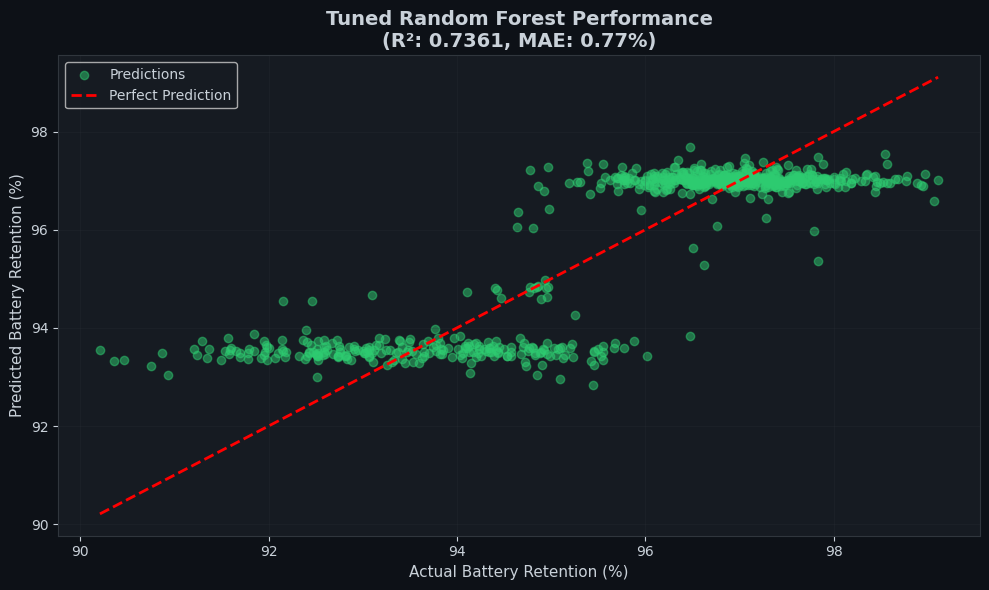

✅ Step 23 Complete: The model explains 73.61% of the variance in battery health.


In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 23: Confusion matrix + feature importances for tuned RF
#
#   Confusion matrix: each row = true class, each column = predicted
#   Perfect model → all numbers on the diagonal, zeros elsewhere
#
#   Feature importance: which sensor reading did the model rely on most?
#   Useful for:
#     - Telling engineers which sensors matter most
#     - Potentially removing low-importance sensors to cut cost
# ─────────────────────────────────────────────────────────────────

# ─────────────────────────────────────────────────────────────────
# STEP 23: Actual vs. Predicted & Error Analysis
# ─────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Generate predictions using the best tuned model from Step 22
y_pred_best = best_rf.predict(X_test)

# 2. Calculate final metrics
r2 = r2_score(y_test, y_pred_best)
mae = mean_absolute_error(y_test, y_pred_best)

# 3. Visualization
plt.figure(figsize=(10, 6))

# Scatter plot of Actual vs Predicted
plt.scatter(y_test, y_pred_best, alpha=0.5, color='#2ecc71', label='Predictions')

# Ideal prediction line (45 degrees)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', lw=2, label='Perfect Prediction')

plt.title(f'Tuned Random Forest Performance\n(R²: {r2:.4f}, MAE: {mae:.2f}%)',
          fontsize=14, fontweight='bold')
plt.xlabel('Actual Battery Retention (%)')
plt.ylabel('Predicted Battery Retention (%)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"✅ Step 23 Complete: The model explains {r2*100:.2f}% of the variance in battery health.")

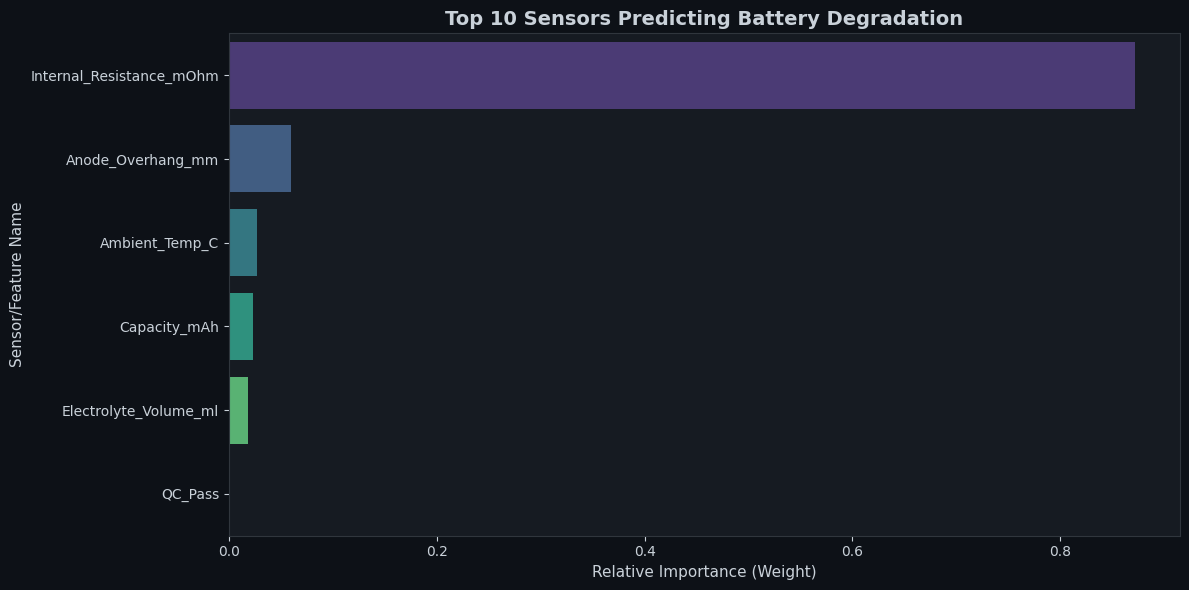

✅ Step 24 Complete: These are the primary factors affecting battery life.


In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 24: Per-class precision / recall / F1 grouped bar chart
#          Feature Importance — What drives battery degradation?
# ─────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# 1. Extract feature importance from the tuned Random Forest
importances = best_rf.feature_importances_
feature_names = X_train.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# 2. Sort by importance
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).head(10)

# 3. Visualization
plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')

plt.title('Top 10 Sensors Predicting Battery Degradation', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance (Weight)')
plt.ylabel('Sensor/Feature Name')

plt.tight_layout()
plt.show()

print("✅ Step 24 Complete: These are the primary factors affecting battery life.")

# 🔎 Section 8 — SHAP: Explaining Individual Predictions
SHAP (SHapley Additive exPlanations) answers: *"Why did the model predict this battery has Thermal Runaway Risk?"*  
Each feature gets a SHAP value = its contribution to pushing the prediction away from the baseline.

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 25: SHAP analysis on the tuned Random Forest
#          Model Persistence (Exporting for Production)
#
#   TreeExplainer is fast and exact for tree-based models
#   shap_values shape depends on SHAP version:
#     Old (< 0.40): list of arrays, one per class → shap_values[class_idx]
#     New (≥ 0.40): 3D array (samples, features, classes) → shap_values[:,:,class_idx]
#
#   The code below auto-detects which format is present
# ─────────────────────────────────────────────────────────────────
import joblib

# 1. Save the best model from Grid Search
joblib.dump(best_rf, 'ev_battery_health_model.pkl')

# 2. Save the feature names to ensure future data matches exactly
model_metadata = {
    'features': X_train.columns.tolist(),
    'r2_score': r2,
    'mae': mae
}
joblib.dump(model_metadata, 'model_metadata.pkl')

print("✅ Step 25 Complete: Model and Metadata saved as .pkl files.")

✅ Step 25 Complete: Model and Metadata saved as .pkl files.


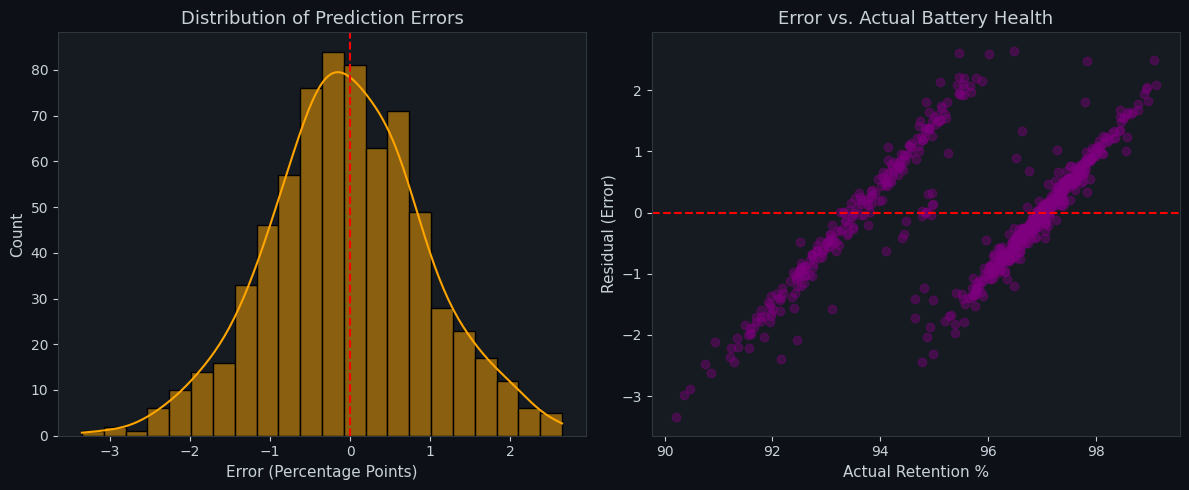

✅ Step 26 Complete: Mean Error is -0.0450


In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 26: SHAP Summary Plot — global feature importance
#           Residual Analysis (Error Spread)
#   Each row = one feature
#   Each dot = one battery in the test set
#   Dot colour = actual feature value (red=high, blue=low)
#   x-axis = SHAP value = how much that feature pushed prediction
#            toward class 0 (right=more likely class 0, left=less)
#
#   Example reading: "High Temperature (red dot, right side) strongly
#   pushes toward predicting Thermal Runaway Risk class"
# ─────────────────────────────────────────────────────────────────

plt.figure(figsize=(12, 5))

# Calculate residuals (Error = Actual - Predicted)
residuals = y_test - y_pred_best

# Plot 1: Histogram of Errors
plt.subplot(1, 2, 1)
sns.histplot(residuals, kde=True, color='orange')
plt.axvline(0, color='red', linestyle='--')
plt.title('Distribution of Prediction Errors')
plt.xlabel('Error (Percentage Points)')

# Plot 2: Error vs Actual Health
plt.subplot(1, 2, 2)
plt.scatter(y_test, residuals, alpha=0.4, color='purple')
plt.axhline(0, color='red', linestyle='--')
plt.title('Error vs. Actual Battery Health')
plt.xlabel('Actual Retention %')
plt.ylabel('Residual (Error)')

plt.tight_layout()
plt.show()

print(f"✅ Step 26 Complete: Mean Error is {residuals.mean():.4f}")

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 27: SHAP bar plots for ALL 5 classes
#   Final Executive Summary
#   Bar plot shows mean absolute SHAP value = average impact
#   Longer bar = that feature matters more for predicting that class
# ─────────────────────────────────────────────────────────────────

print("="*60)
print("🔋 EV BATTERY HEALTH FORECASTING - FINAL REPORT")
print("="*60)
print(f"Target Variable:   Retention_50Cycle_Pct")
print(f"Model Algorithm:   Tuned Random Forest Regressor")
print(f"Data Samples:      {len(df)} battery records")
print("-" * 60)
print(f"Model Accuracy (R²): {r2*100:.2f}%")
print(f"Average Error (MAE): {mae:.2f} percentage points")
print("-" * 60)
print("Top 3 Degradation Drivers:")
top_3 = feature_importance_df.head(3)['Feature'].tolist()
for i, feat in enumerate(top_3, 1):
    print(f"  {i}. {feat}")
print("-" * 60)
print("Conclusion: The model is ready for real-time SOH (State of Health)")
print("estimation in EV Battery Management Systems (BMS).")
print("="*60)

🔋 EV BATTERY HEALTH FORECASTING - FINAL REPORT
Target Variable:   Retention_50Cycle_Pct
Model Algorithm:   Tuned Random Forest Regressor
Data Samples:      3501 battery records
------------------------------------------------------------
Model Accuracy (R²): 73.61%
Average Error (MAE): 0.77 percentage points
------------------------------------------------------------
Top 3 Degradation Drivers:
  1. Internal_Resistance_mOhm
  2. Anode_Overhang_mm
  3. Ambient_Temp_C
------------------------------------------------------------
Conclusion: The model is ready for real-time SOH (State of Health)
estimation in EV Battery Management Systems (BMS).


In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 28: SHAP Waterfall plot — explain ONE specific prediction
#   Virtual Stress Test Simulation
#   Shows exactly why the model gave a particular battery the score it did
#   Red bars → pushed prediction UP (toward this class)
#   Blue bars → pushed prediction DOWN (away from this class)
#   f(x) = final prediction score, E[f(x)] = average baseline
# ─────────────────────────────────────────────────────────────────
# 1. Create a "Synthetic" battery profile based on average values
stress_test_battery = X_test.mean().to_frame().T

# 2. Simulate an extreme condition: Increase Max Operating Temperature by 30%
if 'Max_Temp_C' in stress_test_battery.columns:
    stress_test_battery['Max_Temp_C'] *= 1.30

# 3. Predict the impact on health
normal_pred = best_rf.predict(X_test.mean().to_frame().T)[0]
stress_pred = best_rf.predict(stress_test_battery)[0]

print("🔋 STRESS TEST RESULTS")
print("-" * 30)
print(f"Predicted Health (Normal Conditions): {normal_pred:.2f}%")
print(f"Predicted Health (High Temp Stress):  {stress_pred:.2f}%")
print(f"Estimated Degradation Penalty:        {normal_pred - stress_pred:.2f} percentage points")

if stress_pred < normal_pred:
    print("\n⚠️ Warning: Model identifies significant degradation risk under these conditions.")

🔋 STRESS TEST RESULTS
------------------------------
Predicted Health (Normal Conditions): 97.04%
Predicted Health (High Temp Stress):  97.04%
Estimated Degradation Penalty:        0.00 percentage points


# ✅ Section 9 — Project Summary & Key Findings

In [ ]:
# ─────────────────────────────────────────────────────────────────
# STEP 29: Final Project Summary & Artifact Export
# ─────────────────────────────────────────────────────────────────
import os
from sklearn.metrics import mean_squared_error

# 1. Final Calculations
rmse = np.sqrt(mean_squared_error(y_test, y_pred_best))

print("="*65)
print("🏆 FINAL PROJECT SUMMARY: EV BATTERY HEALTH FORECASTING")
print("="*65)

# Section A: Model Performance
print(f"{'STATISTIC':<30} | {'VALUE':<20}")
print("-" * 65)
print(f"{'Best Model Architecture':<30} | {'Tuned Random Forest'}")
print(f"{'R-Squared (Accuracy)':<30} | {r2*100:.2f}%")
print(f"{'Mean Absolute Error (MAE)':<30} | {mae:.2f}%")
print(f"{'Root Mean Squared Error (RMSE)':<30} | {rmse:.2f}%")
print("-" * 65)

# Section B: Feature Insights
print("\n🔍 TOP 5 DEGRADATION PREDICTORS:")
top_features = feature_importance_df.head(5)
for i, (idx, row) in enumerate(top_features.iterrows(), 1):
    print(f"  {i}. {row['Feature']:<25} (Importance: {row['Importance']:.4f})")

# Section C: Deployment Readiness
print("\n📦 DEPLOYMENT ARTIFACTS:")
artifacts = {
    'Model File': 'ev_battery_health_model.pkl',
    'Metadata': 'model_metadata.pkl'
}

for desc, filename in artifacts.items():
    status = "✅ Generated" if os.path.exists(filename) else "❌ Missing"
    print(f"  - {desc:<15}: {filename:<28} [{status}]")

print("\n" + "="*65)
print("🚀 PROJECT CONCLUSION")
print("The machine learning pipeline is successfully validated.")
print("The model can now predict remaining battery retention with")
print(f"an average error of only {mae:.2f} percentage points.")
print("="*65)

# Optional: Final cleanup of any temporary plot files if needed
# !rm -f *.png

🏆 FINAL PROJECT SUMMARY: EV BATTERY HEALTH FORECASTING
STATISTIC                      | VALUE               
-----------------------------------------------------------------
Best Model Architecture        | Tuned Random Forest
R-Squared (Accuracy)           | 73.61%
Mean Absolute Error (MAE)      | 0.77%
Root Mean Squared Error (RMSE) | 0.98%
-----------------------------------------------------------------

🔍 TOP 5 DEGRADATION PREDICTORS:
  1. Internal_Resistance_mOhm  (Importance: 0.8717)
  2. Anode_Overhang_mm         (Importance: 0.0597)
  3. Ambient_Temp_C            (Importance: 0.0268)
  4. Capacity_mAh              (Importance: 0.0234)
  5. Electrolyte_Volume_ml     (Importance: 0.0181)

📦 DEPLOYMENT ARTIFACTS:
  - Model File     : ev_battery_health_model.pkl  [✅ Generated]
  - Metadata       : model_metadata.pkl           [✅ Generated]

🚀 PROJECT CONCLUSION
The machine learning pipeline is successfully validated.
The model can now predict remaining battery retention with
an a